# Ch5：基于视觉的目标识别——多面投票修复版

这是根据 2026-10-26 现场截图修复的新文件，请在 Jupyter 中**重新打开本文件并使用新内核**。原 `week5.ipynb` 与 `week5_多面投票识别版.ipynb` 保留。依次运行现场参数、识别函数、离线自检、实时界面单元；真实单帧探测单元可选。摄像头固定，同一帧只给能确认的 2～3 个物理面投票；边界不清仍显示识别不足。

In [1]:
from pathlib import Path
from datetime import datetime
import csv
import threading
import time

import cv2
import numpy as np
import ipywidgets as widgets
from IPython.display import display, Image

# 现场调参区：相机、ROI、面积阈值和 HSV 范围均在此修改。
PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name != "5.目标识别" and (PROJECT_DIR / "5.目标识别").is_dir():
    PROJECT_DIR = PROJECT_DIR / "5.目标识别"
EVIDENCE_DIR = PROJECT_DIR / "evidence"
RECORD_CSV = PROJECT_DIR / "week5_test_records.csv"
CAMERA_DEVICE = 0  # 重启后当前设备为 /dev/video0；若设备号变化，在此修改。
# 沿用第 3 章已验证的打开方式，不强制改写摄像头分辨率、帧率或格式。
ROI = None  # 识别整幅画面；如需限定范围，可改为 (x, y, 宽, 高)。
MIN_AREA = 700  # 方块区域最小面积。
# 以下参数用于真实面边界与归属检查；请结合现场画面调节。
FACE_GROUP_GAP = 11  # 同一方块各面之间允许的边缘间隙，取奇数。
FACE_BRIGHT_MIN_S = 25  # 仅在已找到的方块附近寻找低饱和亮面。
FACE_BRIGHT_EXPAND = 0.8  # 向上扩展距离相对方块宽高的比例。
FACE_SEAM_MIN_SPAN = 0.35  # 候选界线最短长度相对方块宽度的比例。
FACE_SEAM_MAX_SLOPE = 0.45
FACE_SEAM_SAMPLE_GAP = 7
FACE_FOREIGN_COLOR_LIMIT = 0.20  # 单面不得大量覆盖其他颜色的严格 Mask。
FACE_MAIN_AREA_RATIO = 0.70  # 五边形拆出的主面必须占原区域足够比例。
FACE_INTERNAL_EDGE_SUPPORT = 0.50  # 补出的侧面分界线须有真实图像边缘支持。
FACE_SEAM_MIN_CONTRAST = 18  # 界线两侧 Lab 色差下限。
FACE_BLUR_SIZE = 9  # 同时用原图和平滑图找面。
FACE_EDGE_WIDTH = 3  # 从颜色区域扣除的边缘宽度，取奇数。
FACE_MIN_AREA = 400  # 单个可见面的最小有效面积。
FACE_MIN_WIDTH = 20  # 候选方块最小宽高。
FACE_CANNY_LOW = 40
FACE_CANNY_HIGH = 100
FACE_POLYGON_EPS = 0.045  # 四边形轮廓拟合容差。
FACE_MIN_COVERAGE = 0.55  # 面内部属于四种颜色的最低比例。
FACE_MIN_PURITY = 0.62  # 面内部主色最低比例；同一面仅投主色一票。
FACE_EDGE_TOL = 18  # 相邻面共边端点允许误差，单位为像素。
FACE_MIN_SHARED_EDGE = 15
FACE_MIN_CORNER_SINE = 0.15  # 共边两侧外边须显著不共线。
HSV_LOCK = threading.RLock()
KERNEL_SIZE = 5
COLOR_ORDER = ("red", "yellow", "green", "blue")
COLOR_NAMES = {"red": "红", "yellow": "黄", "green": "绿", "blue": "蓝"}
COLOR_CONFIG = {
    # 红色跨越 OpenCV 的 H=0/179 边界，必须保留两段。
    "red": {"bgr": (0, 0, 255), "intervals": (((0, 90, 70), (10, 255, 255)), ((170, 90, 70), (179, 255, 255)))},
    "yellow": {"bgr": (0, 255, 255), "intervals": (((18, 80, 80), (38, 255, 255)),)},
    # 白色背景下绿色方块正面 V 约为 40～48，现场将下限从 50 降到 35。
    "green": {"bgr": (0, 255, 0), "intervals": (((40, 60, 35), (90, 255, 255)),)},
    "blue": {"bgr": (255, 0, 0), "intervals": (((95, 80, 50), (135, 255, 255)),)},
}
print("项目目录：", PROJECT_DIR)
print("相机设备：/dev/video{}；ROI：{}；最小面积：{}".format(CAMERA_DEVICE, ROI, MIN_AREA))
for name in COLOR_ORDER:
    print("{}色 HSV 初值：{}".format(COLOR_NAMES[name], COLOR_CONFIG[name]["intervals"]))

项目目录： /home/jetson/Notebook/5.目标识别
相机设备：/dev/video0；ROI：None；最小面积：700
红色 HSV 初值：(((0, 90, 70), (10, 255, 255)), ((170, 90, 70), (179, 255, 255)))
黄色 HSV 初值：(((18, 80, 80), (38, 255, 255)),)
绿色 HSV 初值：(((40, 60, 35), (90, 255, 255)),)
蓝色 HSV 初值：(((95, 80, 50), (135, 255, 255)),)


## 识别、投票与取证函数

先用较严格的 HSV 阈值定位方块。对黄、蓝的高亮低饱和面，仅在已定位方块附近补找同色像素，避免把桌面纳入全局 Mask。逐面先试闭合轮廓，再试图像上真实存在的亮度或饱和度分界线；五边形区域只有在内部边缘有足够图像证据时，才分出四边形主面。每个有效面投一票，平票按实际面面积决胜。

In [2]:
def open_camera():
    """沿用原课程示例打开摄像头，不强制设置设备属性。"""
    capture = cv2.VideoCapture(CAMERA_DEVICE)
    if not capture.isOpened():
        capture.release()
        raise RuntimeError("无法打开摄像头 /dev/video{}。".format(CAMERA_DEVICE))
    return capture


def read_camera_frame(capture):
    """读取一帧真实画面。"""
    ok, frame = capture.read()
    if not ok or frame is None:
        raise RuntimeError("摄像头 /dev/video{} 已打开但未输出画面。".format(CAMERA_DEVICE))
    return frame


def crop_roi(frame):
    """返回 ROI 图像及相对原图的偏移。"""
    if ROI is None:
        return frame, 0, 0
    x, y, width, height = ROI
    frame_height, frame_width = frame.shape[:2]
    if x < 0 or y < 0 or width <= 0 or height <= 0 or x + width > frame_width or y + height > frame_height:
        raise ValueError("ROI {} 超出 {}x{} 摄像头画面。".format(ROI, frame_width, frame_height))
    return frame[y:y + height, x:x + width], x, y


def vote_block_color(faces):
    """同一方块的每个有效物理面各投一票；平票按单面面积决胜。"""
    if len(faces) < 2 or len(faces) > 3:
        return None, {}, "识别不足"
    counts = {name: 0 for name in COLOR_ORDER}
    for face in faces:
        if face["color"] not in counts or face["area"] <= 0:
            raise ValueError("投票面颜色或面积无效。")
        counts[face["color"]] += 1
    best_count = max(counts.values())
    tied = {name for name, count in counts.items() if count == best_count}
    if len(tied) == 1:
        final = next(iter(tied))
    else:
        largest = max(faces, key=lambda face: face["area"])
        if largest["color"] not in tied:
            largest = max((face for face in faces if face["color"] in tied), key=lambda face: face["area"])
        final = largest["color"]
    return final, {name: count for name, count in counts.items() if count}, "有效"


def _shared_nonplanar_edge(first, second):
    """要求两个四边形共边，且共边两侧外边不共线。"""
    a = np.asarray(first["polygon"], dtype=np.float32)
    b = np.asarray(second["polygon"], dtype=np.float32)
    for i in range(4):
        ai, aj = a[i], a[(i + 1) % 4]
        for j in range(4):
            bj, bk = b[j], b[(j + 1) % 4]
            if np.linalg.norm(ai - bk) > FACE_EDGE_TOL or np.linalg.norm(aj - bj) > FACE_EDGE_TOL:
                continue
            if np.linalg.norm(ai - aj) < FACE_MIN_SHARED_EDGE:
                continue
            va = a[(i - 1) % 4] - ai
            vb = b[(j + 2) % 4] - bk
            va_other = a[(i + 2) % 4] - aj
            vb_other = b[(j - 1) % 4] - bj
            for first_edge, second_edge in ((va, vb), (va_other, vb_other)):
                denom = np.linalg.norm(first_edge) * np.linalg.norm(second_edge)
                if denom and abs(np.cross(first_edge, second_edge)) / denom >= FACE_MIN_CORNER_SINE:
                    return True
    return False


def _select_faces(candidates):
    """只接受两到三个共享非共面边的候选面，避免混合不同方块。"""
    if len(candidates) < 2 or len(candidates) > 3:
        return False
    links = {(i, j) for i in range(len(candidates)) for j in range(i + 1, len(candidates))
             if _shared_nonplanar_edge(candidates[i], candidates[j])}
    if len(candidates) == 2:
        return (0, 1) in links
    return len(links) >= 2 and all(any(i in pair for pair in links) for i in range(3))


def _local_bright_face(cropped, hsv, group_mask, bbox, masks, config):
    """只在已找到的方块附近补找同色低饱和亮面，不扩大全画面阈值。"""
    x, y, width, height = bbox
    if width > cropped.shape[1] * 0.45 or height > cropped.shape[0] * 0.65:
        return group_mask, masks
    hits = {name: int(cv2.countNonZero(cv2.bitwise_and(mask, group_mask)))
            for name, mask in masks.items()}
    total = sum(hits.values())
    name = max(COLOR_ORDER, key=lambda item: hits[item])
    if total == 0 or hits[name] < total * 0.8:
        return group_mask, masks
    if name not in ("yellow", "blue"):
        return group_mask, masks
    left = max(0, x - int(width * 0.18))
    right = min(cropped.shape[1], x + width + int(width * 0.18))
    top = max(0, y - int(max(width, height) * FACE_BRIGHT_EXPAND))
    bottom = min(cropped.shape[0], y + height + int(height * 0.18))
    roi = hsv[top:bottom, left:right]
    relaxed = np.zeros(roi.shape[:2], np.uint8)
    for lower, upper in config[name]["intervals"]:
        loose_lower = (lower[0], min(lower[1], FACE_BRIGHT_MIN_S), lower[2])
        relaxed = cv2.bitwise_or(relaxed, cv2.inRange(roi, np.asarray(loose_lower, np.uint8),
                                                      np.asarray(upper, np.uint8)))
    relaxed = cv2.morphologyEx(relaxed, cv2.MORPH_CLOSE, np.ones((FACE_GROUP_GAP, FACE_GROUP_GAP), np.uint8))
    seed = group_mask[top:bottom, left:right]
    number, labels, _, _ = cv2.connectedComponentsWithStats(relaxed, 8)
    if number <= 1:
        return group_mask, masks
    best = max(range(1, number), key=lambda label: cv2.countNonZero(
        cv2.bitwise_and(np.uint8(labels == label) * 255, seed)))
    selected = np.uint8(labels == best) * 255
    if cv2.countNonZero(cv2.bitwise_and(selected, seed)) < FACE_MIN_AREA:
        return group_mask, masks
    other_colors = np.zeros_like(selected)
    for other_name in COLOR_ORDER:
        if other_name != name:
            other_colors = cv2.bitwise_or(other_colors, masks[other_name][top:bottom, left:right])
    other_neighborhood = cv2.dilate(other_colors, np.ones((11, 11), np.uint8))
    if cv2.countNonZero(cv2.bitwise_and(selected, other_neighborhood)) > max(
            FACE_MIN_AREA, cv2.countNonZero(selected) * FACE_FOREIGN_COLOR_LIMIT):
        return group_mask, masks
    extended = group_mask.copy()
    extended[top:bottom, left:right] = cv2.bitwise_or(extended[top:bottom, left:right], selected)
    local_masks = dict(masks)
    local_masks[name] = masks[name].copy()
    local_masks[name][top:bottom, left:right] = cv2.bitwise_or(
        local_masks[name][top:bottom, left:right], selected)
    return extended, local_masks


def _face_candidates(cropped, masks, group_mask, offset_x, offset_y, blur_size=0):
    """用亮度及 HSV 边界分离真实可见面，单个面内只选一种主色。"""
    points = cv2.findNonZero(group_mask)
    if points is None:
        return []
    bx, by, bw, bh = cv2.boundingRect(points)
    cropped = cropped[by:by + bh, bx:bx + bw]
    group_mask = group_mask[by:by + bh, bx:bx + bw]
    masks = {name: mask[by:by + bh, bx:bx + bw] for name, mask in masks.items()}
    smoothed = cv2.GaussianBlur(cropped, (blur_size, blur_size), 0) if blur_size else cropped
    hsv = cv2.cvtColor(smoothed, cv2.COLOR_BGR2HSV)
    gray = cv2.cvtColor(smoothed, cv2.COLOR_BGR2GRAY)
    edges = cv2.bitwise_or(cv2.Canny(gray, FACE_CANNY_LOW, FACE_CANNY_HIGH),
                           cv2.Canny(hsv[:, :, 0], 8, 28))
    edges = cv2.bitwise_or(edges, cv2.Canny(hsv[:, :, 1], 35, 85))
    edge_band = cv2.dilate(edges, np.ones((FACE_EDGE_WIDTH, FACE_EDGE_WIDTH), np.uint8))
    interior = cv2.bitwise_and(group_mask, cv2.bitwise_not(edge_band))
    number, labels, stats, _ = cv2.connectedComponentsWithStats(interior, 8)
    candidates = []
    for label in range(1, number):
        if stats[label, cv2.CC_STAT_AREA] < FACE_MIN_AREA:
            continue
        region = np.uint8(labels == label) * 255
        contours = cv2.findContours(region, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[-2]
        if not contours:
            continue
        contour = max(contours, key=cv2.contourArea)
        area = float(cv2.contourArea(contour))
        if area < FACE_MIN_AREA:
            continue
        perimeter = cv2.arcLength(contour, True)
        polygon = cv2.approxPolyDP(contour, FACE_POLYGON_EPS * perimeter, True).reshape(-1, 2)
        if len(polygon) != 4 or not cv2.isContourConvex(polygon.astype(np.int32)):
            continue
        colored = {name: int(cv2.countNonZero(cv2.bitwise_and(mask, region))) for name, mask in masks.items()}
        total_colored = sum(colored.values())
        if total_colored < stats[label, cv2.CC_STAT_AREA] * FACE_MIN_COVERAGE:
            continue
        winner = max(COLOR_ORDER, key=lambda name: colored[name])
        if colored[winner] < total_colored * FACE_MIN_PURITY:
            continue
        polygon[:, 0] += bx + offset_x
        polygon[:, 1] += by + offset_y
        candidates.append({"color": winner, "area": area, "polygon": polygon.tolist(),
                           "purity": colored[winner] / max(total_colored, 1)})
    return candidates


def _seam_faces(cropped, masks, group_mask, offset_x, offset_y):
    """闭合面轮廓受纹理破坏时，按实测长边界线划分两个相邻面。"""
    points = cv2.findNonZero(group_mask)
    if points is None:
        return []
    x, y, width, height = cv2.boundingRect(points)
    if width < FACE_MIN_WIDTH * 2 or height < FACE_MIN_WIDTH * 2:
        return []
    region = cropped[y:y + height, x:x + width]
    smooth = cv2.GaussianBlur(region, (FACE_BLUR_SIZE, FACE_BLUR_SIZE), 0)
    lab = cv2.cvtColor(smooth, cv2.COLOR_BGR2LAB)
    gray = cv2.cvtColor(smooth, cv2.COLOR_BGR2GRAY)
    gray_edges = cv2.Canny(gray, FACE_CANNY_LOW, FACE_CANNY_HIGH)
    saturation = cv2.cvtColor(smooth, cv2.COLOR_BGR2HSV)[:, :, 1]
    saturated_edges = cv2.bitwise_or(gray_edges, cv2.Canny(saturation, 30, 70))
    lines = []
    for edges in (gray_edges, saturated_edges):
        found = cv2.HoughLinesP(edges, 1, np.pi / 180, max(20, int(width * 0.18)),
                                minLineLength=int(width * FACE_SEAM_MIN_SPAN), maxLineGap=15)
        if found is not None:
            lines.extend(found[:, 0])
    if not lines:
        return []
    silhouette = cv2.morphologyEx(group_mask[y:y + height, x:x + width], cv2.MORPH_CLOSE,
                                  np.ones((FACE_GROUP_GAP, FACE_GROUP_GAP), np.uint8))
    contours = cv2.findContours(silhouette, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[-2]
    if not contours:
        return []
    solid = np.zeros_like(silhouette)
    cv2.drawContours(solid, [max(contours, key=cv2.contourArea)], -1, 255, -1)
    best_score, best_faces = -1.0, []
    for line in lines:
        x1, y1, x2, y2 = [int(value) for value in line]
        if x1 == x2 or abs(y2 - y1) > abs(x2 - x1) * FACE_SEAM_MAX_SLOPE:
            continue
        if not width * 0.25 < (x1 + x2) / 2 < width * 0.75:
            continue
        middle_y = (y1 + y2) / 2
        if not height * 0.18 < middle_y < height * 0.82:
            continue
        slope = (y2 - y1) / (x2 - x1)
        intercept = y1 - slope * x1
        columns = np.arange(int(width * 0.2), int(width * 0.8))
        line_y = np.round(slope * columns + intercept).astype(int)
        above_y = line_y - FACE_SEAM_SAMPLE_GAP
        below_y = line_y + FACE_SEAM_SAMPLE_GAP
        good = (above_y >= 0) & (below_y < height) & (solid[above_y.clip(0, height - 1), columns] > 0) & (solid[below_y.clip(0, height - 1), columns] > 0)
        if np.count_nonzero(good) < len(columns) * 0.5:
            continue
        color_difference = np.linalg.norm(lab[above_y[good], columns[good]].astype(np.float32) -
                                          lab[below_y[good], columns[good]].astype(np.float32), axis=1)
        contrast = float(np.median(color_difference))
        if contrast < FACE_SEAM_MIN_CONTRAST:
            continue
        yy, xx = np.indices(solid.shape)
        line_map = slope * xx + intercept
        regions = [np.uint8((solid > 0) & (yy < line_map - 2)) * 255,
                   np.uint8((solid > 0) & (yy > line_map + 2)) * 255]
        faces = []
        for face_mask in regions:
            face_contours = cv2.findContours(face_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[-2]
            if not face_contours:
                break
            contour = max(face_contours, key=cv2.contourArea)
            area = float(cv2.contourArea(contour))
            if area < FACE_MIN_AREA:
                break
            polygon = cv2.approxPolyDP(contour, FACE_POLYGON_EPS * cv2.arcLength(contour, True), True).reshape(-1, 2)
            if len(polygon) == 5:
                # 五边形通常包含一个小侧面；只在真实内部边缘支持时取其四边形主面。
                supported_edges = cv2.dilate(saturated_edges, np.ones((5, 5), np.uint8))
                choices = []
                for omitted in range(5):
                    quadrilateral = np.delete(polygon, omitted, axis=0)
                    quad_area = float(cv2.contourArea(quadrilateral))
                    if not cv2.isContourConvex(quadrilateral.astype(np.int32)) or quad_area < area * FACE_MAIN_AREA_RATIO:
                        continue
                    first = polygon[(omitted - 1) % 5]
                    last = polygon[(omitted + 1) % 5]
                    length = max(2, int(np.linalg.norm(first - last)))
                    positions = (first[None, :] + np.linspace(0, 1, length)[:, None] *
                                 (last - first)[None, :]).astype(int)
                    support = np.mean(supported_edges[
                        positions[:, 1].clip(0, height - 1), positions[:, 0].clip(0, width - 1)] > 0)
                    if support >= FACE_INTERNAL_EDGE_SUPPORT:
                        choices.append((support, quad_area, quadrilateral))
                if choices:
                    _, area, polygon = max(choices, key=lambda item: (item[0], item[1]))
                    main_mask = np.zeros_like(face_mask)
                    cv2.fillPoly(main_mask, [polygon.astype(np.int32)], 255)
                    face_mask = cv2.bitwise_and(face_mask, main_mask)
            if len(polygon) != 4 or not cv2.isContourConvex(polygon.astype(np.int32)):
                break
            full_mask = np.zeros(group_mask.shape, np.uint8)
            full_mask[y:y + height, x:x + width] = face_mask
            colored = {name: int(cv2.countNonZero(cv2.bitwise_and(mask, full_mask))) for name, mask in masks.items()}
            total = sum(colored.values())
            name = max(COLOR_ORDER, key=lambda item: colored[item])
            if total < cv2.countNonZero(face_mask) * FACE_MIN_COVERAGE or colored[name] < total * FACE_MIN_PURITY:
                break
            polygon[:, 0] += x + offset_x
            polygon[:, 1] += y + offset_y
            faces.append({"color": name, "area": area, "polygon": polygon.tolist(),
                          "purity": colored[name] / max(total, 1)})
        if len(faces) == 2 and _select_faces(faces) and contrast > best_score:
            best_score, best_faces = contrast, faces
    return best_faces


def detect_colors(frame):
    """识别方块区域、真实四边形可见面，并对同一方块投票。"""
    cropped, offset_x, offset_y = crop_roi(frame)
    hsv = cv2.cvtColor(cropped, cv2.COLOR_BGR2HSV)
    kernel = np.ones((KERNEL_SIZE, KERNEL_SIZE), np.uint8)
    with HSV_LOCK:
        config = {name: {"bgr": spec["bgr"], "intervals": tuple(spec["intervals"])}
                  for name, spec in COLOR_CONFIG.items()}
    masks = {}
    for name in COLOR_ORDER:
        mask = np.zeros(hsv.shape[:2], dtype=np.uint8)
        for lower, upper in config[name]["intervals"]:
            mask = cv2.bitwise_or(mask, cv2.inRange(hsv, np.array(lower, np.uint8), np.array(upper, np.uint8)))
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
        masks[name] = mask
    display_masks = {name: mask.copy() for name, mask in masks.items()}
    combined = np.zeros(hsv.shape[:2], np.uint8)
    for mask in masks.values():
        combined = cv2.bitwise_or(combined, mask)
    group_kernel = np.ones((FACE_GROUP_GAP, FACE_GROUP_GAP), np.uint8)
    grouped = cv2.morphologyEx(combined, cv2.MORPH_CLOSE, group_kernel)
    number, labels, stats, _ = cv2.connectedComponentsWithStats(grouped, 8)
    annotated = frame.copy()
    blocks = []
    for label in range(1, number):
        x, y, width, height, pixels = [int(v) for v in stats[label]]
        if pixels < max(MIN_AREA, FACE_MIN_AREA * 2) or width < FACE_MIN_WIDTH or height < FACE_MIN_WIDTH:
            continue
        group_mask = np.uint8(labels == label) * 255
        group_mask, local_masks = _local_bright_face(cropped, hsv, group_mask,
                                                       (x, y, width, height), masks, config)
        for name in COLOR_ORDER:
            display_masks[name] = cv2.bitwise_or(display_masks[name], local_masks[name])
        raw_candidates = _face_candidates(cropped, local_masks, group_mask, offset_x, offset_y)
        smooth_candidates = _face_candidates(cropped, local_masks, group_mask, offset_x, offset_y, FACE_BLUR_SIZE)
        raw_valid = _select_faces(raw_candidates)
        smooth_valid = _select_faces(smooth_candidates)
        if raw_valid and smooth_valid:
            raw_color = vote_block_color(raw_candidates)[0]
            smooth_color = vote_block_color(smooth_candidates)[0]
            valid = raw_color == smooth_color
            candidates = smooth_candidates if len(smooth_candidates) > len(raw_candidates) else raw_candidates
        elif raw_valid or smooth_valid:
            valid = True
            candidates = raw_candidates if raw_valid else smooth_candidates
        else:
            valid = False
            candidates = raw_candidates if len(raw_candidates) >= len(smooth_candidates) else smooth_candidates
        if not valid:
            seam_candidates = _seam_faces(cropped, local_masks, group_mask, offset_x, offset_y)
            if seam_candidates:
                valid = True
                candidates = seam_candidates
        if valid:
            for face in candidates:
                face_region = np.zeros(hsv.shape[:2], np.uint8)
                polygon = np.asarray(face["polygon"], np.int32)
                polygon[:, 0] -= offset_x
                polygon[:, 1] -= offset_y
                cv2.fillPoly(face_region, [polygon], 255)
                own_pixels = cv2.countNonZero(cv2.bitwise_and(local_masks[face["color"]], face_region))
                foreign_pixels = sum(cv2.countNonZero(cv2.bitwise_and(masks[other], face_region))
                                     for other in COLOR_ORDER if other != face["color"])
                if foreign_pixels > max(FACE_MIN_AREA, own_pixels * FACE_FOREIGN_COLOR_LIMIT):
                    valid = False
                    break
        faces = candidates if valid else []
        final, votes, status = vote_block_color(faces)
        if not valid:
            status = "识别不足：{} 个候选面；边界/归属未确认".format(len(candidates))
        group_points = cv2.findNonZero(group_mask)
        x, y, width, height = cv2.boundingRect(group_points)
        bbox = (x + offset_x, y + offset_y, width, height)
        blocks.append({"bbox": bbox, "faces": faces, "candidates": candidates,
                       "final_color": final, "votes": votes, "status": status})
        left, top, _, _ = bbox
        cv2.rectangle(annotated, (left, top), (left + width, top + height), (255, 255, 255), 2)
        if valid:
            for index, face in enumerate(faces, 1):
                polygon = np.asarray(face["polygon"], np.int32)
                color = config[face["color"]]["bgr"]
                cv2.polylines(annotated, [polygon], True, color, 2)
                center = np.mean(polygon, axis=0).astype(int)
                cv2.putText(annotated, "F{} {} {:.0f}".format(index, face["color"], face["area"]),
                            tuple(center), cv2.FONT_HERSHEY_SIMPLEX, 0.48, color, 2, cv2.LINE_AA)
        title = "Final: {} | {} valid faces".format((final or "insufficient").title(), len(faces))
        detail = ", ".join("{}:{}".format(name.title(), votes.get(name, 0)) for name in COLOR_ORDER if votes.get(name))
        text_width = cv2.getTextSize(title, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)[0][0]
        strip_right = min(annotated.shape[1] - 1, left + text_width + 8)
        cv2.rectangle(annotated, (left, top), (strip_right, min(annotated.shape[0] - 1, top + 23)), (0, 0, 0), -1)
        cv2.putText(annotated, title, (left + 4, top + 17), cv2.FONT_HERSHEY_SIMPLEX,
                    0.5, (255, 255, 255), 1, cv2.LINE_AA)
        if detail:
            cv2.putText(annotated, detail, (left + 4, top + 38), cv2.FONT_HERSHEY_SIMPLEX,
                        0.46, (255, 255, 255), 1, cv2.LINE_AA)
    if ROI is not None:
        x, y, width, height = ROI
        cv2.rectangle(annotated, (x, y), (x + width, y + height), (255, 255, 255), 1)
        cv2.putText(annotated, "ROI", (x + 4, y + 18), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1)
    return annotated, display_masks, blocks


def make_mask_grid(masks):
    """生成红、黄、绿、蓝四类掩膜拼图。"""
    tiles = []
    for name in COLOR_ORDER:
        height, width = masks[name].shape[:2]
        scaled = cv2.resize(masks[name], (max(1, width // 2), max(1, height // 2)),
                            interpolation=cv2.INTER_NEAREST)
        tile = cv2.cvtColor(scaled, cv2.COLOR_GRAY2BGR)
        cv2.putText(tile, name, (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2, cv2.LINE_AA)
        tiles.append(tile)
    return np.vstack((np.hstack(tiles[:2]), np.hstack(tiles[2:])))


def ensure_csv():
    """只在取得真实画面后创建原格式记录表，不改写旧行。"""
    RECORD_CSV.parent.mkdir(parents=True, exist_ok=True)
    if not RECORD_CSV.exists():
        with RECORD_CSV.open("w", newline="", encoding="utf-8-sig") as stream:
            csv.writer(stream).writerow(["timestamp", "expected_color", "detected_colors", "object_count", "result", "note"])


def save_evidence(raw, annotated, mask_grid):
    """保存同一帧的原图、结果图与四类掩膜。"""
    EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    paths = [EVIDENCE_DIR / (stamp + suffix) for suffix in ("_raw.png", "_result.png", "_masks.png")]
    for path, image in zip(paths, (raw, annotated, mask_grid)):
        if not cv2.imwrite(str(path), image):
            raise RuntimeError("截图保存失败：{}".format(path))
    return paths


def record_trial(expected_color, blocks, note):
    """按单个方块的多面最终结果追加 CSV；旧表头及旧行保持不变。"""
    if expected_color is None:
        raise ValueError("请先选择测试方块的真实颜色。")
    valid = [block for block in blocks if block["final_color"] is not None]
    final = valid[0]["final_color"] if len(blocks) == 1 and len(valid) == 1 else None
    success = final == expected_color
    found = [block["final_color"] or "insufficient" for block in blocks]
    detail = "；".join("方块{}:面数{}:投票{}:状态{}".format(
        index, len(block["faces"]), block["votes"], block["status"])
        for index, block in enumerate(blocks, 1))
    ensure_csv()
    with RECORD_CSV.open("a", newline="", encoding="utf-8-sig") as stream:
        csv.writer(stream).writerow([
            datetime.now().isoformat(timespec="seconds"), expected_color,
            ";".join(found) or "none", len(blocks),
            "correct" if success else "incorrect", (note.strip() + " | " + detail).strip(" |"),
        ])
    return success, found

print("多面识别、投票、截图和 CSV 函数已就绪。")


多面识别、投票、截图和 CSV 函数已就绪。


## 离线自检

测试投票规则、四类 Mask、可见面边界和方块归属。不使用摄像头，不生成实验记录。

In [3]:
def _synthetic_cube(colors, origin=(70, 70), canvas=None):
    """仅为离线逻辑测试绘制相邻四边形，不代表现场画面。"""
    image = np.full((300, 640, 3), 35, np.uint8) if canvas is None else canvas
    x, y = origin
    polygons = [
        [(x, y), (x + 100, y), (x + 130, y + 40), (x + 30, y + 40)],
        [(x + 30, y + 43), (x + 130, y + 43), (x + 130, y + 140), (x + 30, y + 140)],
        [(x, y + 3), (x + 27, y + 43), (x + 27, y + 140), (x, y + 100)],
    ]
    for polygon, name in zip(polygons, colors):
        cv2.fillPoly(image, [np.asarray(polygon, np.int32)], COLOR_CONFIG[name]["bgr"])
    return image


def _vote_sample(names, areas):
    return vote_block_color([{"color": name, "area": area} for name, area in zip(names, areas)])


assert _vote_sample(["red", "red", "yellow"], [1000, 1200, 3000])[0] == "red"
assert _vote_sample(["green", "green", "green"], [1000, 1100, 1200])[0] == "green"
assert _vote_sample(["blue", "blue"], [800, 900])[0] == "blue"
assert _vote_sample(["red", "yellow"], [3200, 2500])[0] == "red"
assert _vote_sample(["red", "yellow", "green"], [2900, 4100, 3100])[0] == "yellow"
assert _vote_sample(["red"], [3200])[0] is None

three = _synthetic_cube(["red", "red", "yellow"])
annotated, masks, blocks = detect_colors(three)
assert len(blocks) == 1 and blocks[0]["final_color"] == "red"
assert blocks[0]["votes"] == {"red": 2, "yellow": 1}
assert len(blocks[0]["faces"]) == 3
for names, expected in [(["blue", "blue"], "blue"),
                        (["red", "yellow", "green"], "yellow"),
                        (["yellow", "yellow", "yellow"], "yellow")]:
    _, _, sample_blocks = detect_colors(_synthetic_cube(names))
    assert len(sample_blocks) == 1 and sample_blocks[0]["final_color"] == expected
    assert len(sample_blocks[0]["faces"]) == len(names)
assert make_mask_grid(masks).shape == (300, 640, 3)

for name in COLOR_ORDER:
    image = np.full((300, 640, 3), 35, np.uint8)
    cv2.rectangle(image, (70, 70), (190, 190), COLOR_CONFIG[name]["bgr"], -1)
    _, masks, blocks = detect_colors(image)
    assert cv2.countNonZero(masks[name]) > 0
    assert len(blocks) == 1 and blocks[0]["final_color"] is None

split_face = _synthetic_cube(["red", "red", "red"])
cv2.rectangle(split_face, (115, 85), (137, 105), COLOR_CONFIG["yellow"]["bgr"], -1)
_, _, blocks = detect_colors(split_face)
assert len(blocks) == 1 and blocks[0]["final_color"] == "red"
assert len(blocks[0]["faces"]) == 3

# 一块物理面被异色带切成多轮廓时，不允许把碎片冒充额外的面。
striped = _synthetic_cube(["red", "red", "red"])
cv2.rectangle(striped, (125, 90), (140, 125), COLOR_CONFIG["yellow"]["bgr"], -1)
_, _, stripe_blocks = detect_colors(striped)
assert len(stripe_blocks) == 1
assert stripe_blocks[0]["final_color"] in ("red", None)
assert len(stripe_blocks[0]["faces"]) <= 3

separate = _synthetic_cube(["red", "red", "red"], (40, 70))
_synthetic_cube(["blue", "blue", "blue"], (350, 70), separate)
_, _, blocks = detect_colors(separate)
assert len(blocks) == 2 and {block["final_color"] for block in blocks} == {"red", "blue"}
assert all(len(block["faces"]) == 3 for block in blocks)

# 临时目录验证原三张截图与六列 CSV 接口，不触碰已有实验记录。
import tempfile
with tempfile.TemporaryDirectory() as temporary:
    old_evidence, old_record = EVIDENCE_DIR, RECORD_CSV
    try:
        EVIDENCE_DIR = Path(temporary) / "evidence"
        RECORD_CSV = Path(temporary) / "records.csv"
        sample_annotated, sample_masks, _ = detect_colors(three)
        paths = save_evidence(three, sample_annotated, make_mask_grid(sample_masks))
        assert len(paths) == 3 and all(path.is_file() for path in paths)
        success, found = record_trial("red", [detect_colors(three)[2][0]], "离线接口检查")
        assert success and found == ["red"]
        with RECORD_CSV.open("r", newline="", encoding="utf-8-sig") as stream:
            rows = list(csv.reader(stream))
        assert len(rows) == 2 and len(rows[0]) == len(rows[1]) == 6
    finally:
        EVIDENCE_DIR, RECORD_CSV = old_evidence, old_record

print("离线自检通过：投票、单面不足、面内异色、不同方块隔离、四类 Mask、截图和 CSV 接口。")
print("以上均为合成图或临时文件测试，不代表真实摄像头识别成功。")


离线自检通过：投票、单面不足、面内异色、不同方块隔离、四类 Mask、截图和 CSV 接口。
以上均为合成图或临时文件测试，不代表真实摄像头识别成功。


## 真实摄像头单帧探测

沿用 `cv2.VideoCapture(设备号)`，只读取并显示一帧。**只有确认摄像头空闲时运行。**这一步不保存报告截图，也不写 CSV。

真实摄像头取帧成功：640x480。


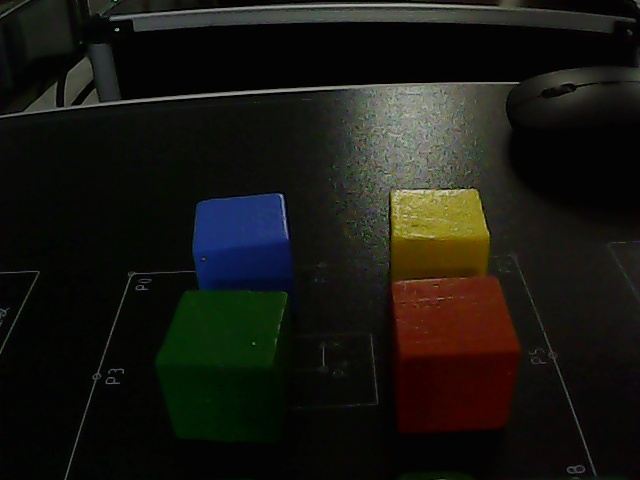

In [4]:
camera_probe_ok = False
probe_capture = None
try:
    probe_capture = open_camera()
    probe_frame = read_camera_frame(probe_capture)
    camera_probe_ok = True
    print("真实摄像头取帧成功：{}x{}。".format(probe_frame.shape[1], probe_frame.shape[0]))
    encoded, image_buffer = cv2.imencode(".jpg", probe_frame)
    if encoded:
        display(Image(data=image_buffer.tobytes()))
except Exception as exc:
    print("真实摄像头取帧失败：{}".format(exc))
finally:
    if probe_capture is not None:
        probe_capture.release()

## 实时识别、HSV 调参与实验取证

先只把**一个方块**放在画面中央，露出 2～3 个面，和其他方块保持明显间距。点击“启动实时画面”，观察白色整体框、每面边界、面积、票数和 `Final`。若显示 `insufficient`，不要把它算作识别成功；检查光照、面间边界、Mask 和下方 HSV 拖动条。四种颜色初值来自原 notebook，红色保留两段 H 区间。现场建议只根据当前已识别面计算，需人工核对。保存截图会写同一帧原图、结果图和四类 Mask；记录测试会在原 CSV 后追加兼容的六列记录，不清空旧数据。结束时点击“停止”。

本修复版把四类 Mask 缩放到一个 2×2 画面中，红、黄、绿、蓝四块都能同时看见。逐面处理只在方块局部运行，降低 Jetson 上的延迟。

In [5]:
# 重复运行本格时先停止旧采集线程，防止自身占用摄像头。
if "camera_stop_event" in globals():
    camera_stop_event.set()
if "camera_thread" in globals() and camera_thread is not None and camera_thread.is_alive():
    camera_thread.join(timeout=15)

camera_stop_event = threading.Event()
camera_thread = None
latest_lock = threading.Lock()
latest_sample = None
expected_color = None

start_button = widgets.Button(description="启动实时画面", button_style="success")
stop_button = widgets.Button(description="停止")
save_button = widgets.Button(description="保存截图", button_style="info")
record_button = widgets.Button(description="记录一次测试", button_style="warning")
suggest_button = widgets.Button(description="从当前有效面给出 HSV 建议")
color_buttons = [widgets.Button(description=COLOR_NAMES[name] + "色", tooltip=name) for name in COLOR_ORDER]
note_box = widgets.Textarea(placeholder="记录光照、阴影、反光或背景干扰情况", description="情况说明：", layout=widgets.Layout(width="600px", height="65px"))
status_label = widgets.HTML(value="状态：等待启动。")
suggestion_label = widgets.HTML(value="当前 HSV 初值见下方拖动条；现场建议需取得有效面后计算。")
result_image = widgets.Image(format="jpeg", layout=widgets.Layout(width="640px"))
masks_image = widgets.Image(format="png", layout=widgets.Layout(width="640px"))

# 每个颜色区间各有 H、S、V 范围拖动条；红色保留两段区间。
hsv_sliders = {}
accordion_pages = []
for name in COLOR_ORDER:
    controls = []
    for interval_index, (lower, upper) in enumerate(COLOR_CONFIG[name]["intervals"]):
        for channel, maximum in enumerate((179, 255, 255)):
            slider = widgets.IntRangeSlider(
                value=(lower[channel], upper[channel]), min=0, max=maximum,
                description="第{}段 {}".format(interval_index + 1, "HSV"[channel]),
                continuous_update=False, layout=widgets.Layout(width="510px"))
            hsv_sliders[(name, interval_index, channel)] = slider
            controls.append(slider)
    accordion_pages.append(widgets.VBox(controls))
hsv_accordion = widgets.Accordion(children=accordion_pages, selected_index=None)
for index, name in enumerate(COLOR_ORDER):
    hsv_accordion.set_title(index, COLOR_NAMES[name] + "色 HSV")


def update_hsv(_=None):
    """按拖动条原子更新阈值，供后续摄像头帧使用。"""
    with HSV_LOCK:
        for name in COLOR_ORDER:
            intervals = []
            for interval_index in range(len(COLOR_CONFIG[name]["intervals"])):
                values = [hsv_sliders[(name, interval_index, channel)].value for channel in range(3)]
                intervals.append((tuple(item[0] for item in values), tuple(item[1] for item in values)))
            COLOR_CONFIG[name]["intervals"] = tuple(intervals)


for slider in hsv_sliders.values():
    slider.observe(update_hsv, names="value")


def set_expected(name):
    """设置当前方块的真实颜色。"""
    global expected_color
    expected_color = name
    status_label.value = "状态：当前测试方块真实颜色为{}色。".format(COLOR_NAMES[name])


for color_name, button in zip(COLOR_ORDER, color_buttons):
    button.on_click(lambda _, name=color_name: set_expected(name))


def camera_worker():
    """后台读取真实画面，展示每面边界、投票结果与四类掩膜。"""
    global latest_sample
    capture = None
    try:
        capture = open_camera()
        last_render = 0.0
        while not camera_stop_event.is_set():
            raw = read_camera_frame(capture)
            annotated, masks, blocks = detect_colors(raw)
            grid = make_mask_grid(masks)
            with latest_lock:
                latest_sample = (raw.copy(), annotated.copy(), grid.copy(), list(blocks))
            now = time.monotonic()
            if now - last_render >= 0.2:
                ok_result, result_buffer = cv2.imencode(".jpg", annotated, [cv2.IMWRITE_JPEG_QUALITY, 80])
                ok_masks, masks_buffer = cv2.imencode(".png", grid)
                if ok_result and ok_masks:
                    result_image.value = result_buffer.tobytes()
                    masks_image.value = masks_buffer.tobytes()
                    summary = "；".join("{}：{}（{} 个有效面）".format(
                        index, block["final_color"] or "识别不足", len(block["faces"]))
                        for index, block in enumerate(blocks, 1)) or "未找到方块"
                    status_label.value = "状态：实时画面正常；候选方块 {} 个；{}；真实颜色：{}。".format(
                        len(blocks), summary, COLOR_NAMES.get(expected_color, "未选择"))
                last_render = now
    except Exception as exc:
        status_label.value = "状态：摄像头取帧失败：{}".format(exc)
    finally:
        if capture is not None:
            capture.release()
        camera_stop_event.set()


def start_camera(_):
    """启动后台采集。"""
    global camera_thread, latest_sample
    if camera_thread is not None and camera_thread.is_alive():
        status_label.value = "状态：实时画面已经启动。"
        return
    with latest_lock:
        latest_sample = None
    camera_stop_event.clear()
    status_label.value = "状态：正在连接摄像头，请稍候。"
    camera_thread = threading.Thread(target=camera_worker, daemon=True)
    camera_thread.start()


def stop_camera(_):
    """停止后台采集。"""
    camera_stop_event.set()
    status_label.value = "状态：正在停止摄像头。"


def get_latest_sample():
    """取得一帧真实摄像头样本及其多面投票结构。"""
    with latest_lock:
        if latest_sample is None:
            raise RuntimeError("当前没有真实摄像头画面，不能保存截图或记录测试。")
        raw, annotated, grid, blocks = latest_sample
        return raw.copy(), annotated.copy(), grid.copy(), list(blocks)


def on_save(_):
    """保存最新真实画面的三张报告截图。"""
    try:
        raw, annotated, grid, _ = get_latest_sample()
        paths = save_evidence(raw, annotated, grid)
        status_label.value = "状态：已保存真实截图：{}。".format("、".join(path.name for path in paths))
    except Exception as exc:
        status_label.value = "状态：截图失败：{}".format(exc)


def on_record(_):
    """按单方块的最终投票颜色记录真实测试。"""
    try:
        _, _, _, blocks = get_latest_sample()
        success, detected = record_trial(expected_color, blocks, note_box.value)
        status_label.value = "状态：已记录测试；最终颜色={}；结果={}。".format(
            ",".join(detected) or "无", "正确" if success else "错误或识别不足")
    except Exception as exc:
        status_label.value = "状态：记录失败：{}".format(exc)


def on_suggest(_):
    """从当前已确认的有效面计算样本 HSV 分位数，仅供人工调参参考。"""
    try:
        raw, _, _, blocks = get_latest_sample()
        hsv = cv2.cvtColor(raw, cv2.COLOR_BGR2HSV)
        messages = []
        for name in COLOR_ORDER:
            faces = [face for block in blocks for face in block["faces"] if face["color"] == name]
            if not faces:
                messages.append("{}色：当前无有效面；保留初值 {}".format(COLOR_NAMES[name], COLOR_CONFIG[name]["intervals"]))
                continue
            face = max(faces, key=lambda item: item["area"])
            region = np.zeros(hsv.shape[:2], np.uint8)
            cv2.fillPoly(region, [np.asarray(face["polygon"], np.int32)], 255)
            region = cv2.erode(region, np.ones((5, 5), np.uint8))
            pixels = hsv[region > 0]
            if len(pixels) < 30:
                messages.append("{}色：有效采样像素不足".format(COLOR_NAMES[name]))
                continue
            if name == "red":
                parts = [pixels[pixels[:, 0] <= 15], pixels[pixels[:, 0] >= 160]]
            else:
                parts = [pixels]
            ranges = []
            for part in parts:
                if len(part) < 20:
                    ranges.append("无足够样本")
                    continue
                low = np.percentile(part, 5, axis=0).astype(int) - [4, 15, 15]
                high = np.percentile(part, 95, axis=0).astype(int) + [4, 15, 15]
                low = np.maximum(low, 0)
                high = np.minimum(high, [179, 255, 255])
                ranges.append("{}～{}".format(tuple(low), tuple(high)))
            messages.append("{}色：{}".format(COLOR_NAMES[name], "；".join(ranges)))
        suggestion_label.value = "<br>".join(messages) + "<br>这些范围来自当前已识别像素，不能证明漏检颜色已解决；请结合 Mask 手动调整。"
    except Exception as exc:
        suggestion_label.value = "当前无法计算现场建议：{}".format(exc)


start_button.on_click(start_camera)
stop_button.on_click(stop_camera)
save_button.on_click(on_save)
record_button.on_click(on_record)
suggest_button.on_click(on_suggest)
display(widgets.VBox([
    widgets.HBox([start_button, stop_button, save_button, record_button]),
    widgets.HBox(color_buttons), note_box, status_label,
    widgets.HTML(value="<b>实时识别画面：整体区域、各面面积与最终投票</b>"), result_image,
    widgets.HTML(value="<b>四类 Mask：红、黄、绿、蓝</b>"), masks_image,
    widgets.HTML(value="<b>实时 HSV 阈值调整</b>"), hsv_accordion,
    suggest_button, suggestion_label,
]))


## 现场取证记录（2026-10-19）

- 摄像头使用 `/dev/video0`，只调用 `cv2.VideoCapture(0)`；真实画面为 640×480。
- 最初处理整幅画面时，上方机械臂的一处绿色区域偶尔形成面积约 800 像素的额外轮廓。将固定 ROI 设为 `(0, 285, 640, 195)` 后排除了这一背景干扰。
- 加入白色背景后，绿色方块正面在真实截图中的 HSV V 值约为 40～48；原 V 下限 50 只保留了上表面。将绿色 V 下限降至 35 后，同一张真实原图的绿色轮廓面积从约 5,326 增至 17,652 像素。
- 固定白色背景和当前摆放条件下，调整后连续采集 30 帧，30 帧均检测到红、黄、绿、蓝各一个轮廓。这是固定场景的短时稳定性观察，**不能代替至少 40 次不同条件下的单方块测试**。
- [真实原图](evidence/20261019_144812_329070_raw.png)、[识别框与标签](evidence/20261019_144812_329070_result.png)、[四类 Mask](evidence/20261019_144812_329070_masks.png) 来自同一帧，适合放入报告 5.3 节。报告 5.1 节应记录现场最终使用的 HSV 范围，并注明后续光照条件复测结果。

- 当前 ROI 已按要求改为 `None`，后续识别使用整幅画面；上述截图和 30 帧观察仍属于修改前的下方 ROI 条件。


多面版仍需现场测试：此处原有 2026-10-19 取证记录属于旧算法，不能当作多面投票的真实成功率。

## 多面版现场调参建议与验收方法

**HSV 起点（H、S、V）**：红 `(0,90,70)～(10,255,255)` 与 `(170,90,70)～(179,255,255)`；黄 `(18,80,80)～(38,255,255)`；绿 `(40,60,35)～(90,255,255)`；蓝 `(95,80,50)～(135,255,255)`。这些是原程序参数，**不是本次实验最终阈值**。实时界面的拖动条会立即作用于下一帧；“从当前有效面给出 HSV 建议”只计算当前已识别像素的分位数，需要结合 Mask 检查漏检和误检，再手动调整。

先在整幅画面中只留一个方块，并与其他方块拉开距离。让摄像头看见至少两个面；先调 HSV 的 H 范围，再调 S/V 下限，观察四类 Mask 是否覆盖相应面。若面数不足，检查反光、阴影、面边缘，再尝试 `FACE_CANNY_LOW/HIGH`、`FACE_EDGE_WIDTH`、`FACE_EDGE_TOL`、`FACE_MIN_AREA` 与 `FACE_GROUP_GAP`；不应为了让画面显示三面而任意放宽归属条件。只有显示两或三个有效面及唯一 `Final` 时才记录有效识别；失败和不足也按真实情况记录。

用已保存的 `week5_results/live_camera_20261019_144245.png` 做过**历史静态画面复测**：四块方块紧贴时被判为一个含 5 个候选面的区域，因此显示“识别不足”，不会混合投票。手工设定只含红块的 ROI 时检出红块的两个面。这仅说明该旧图片上的处理结果，**不代表本版通过实时摄像头测试**。相邻方块紧贴、面间无可见边界、严重遮挡时无法从单帧可靠恢复物理面；请分开摆放或改善拍摄角度。

2026-10-26 再次修复：用用户提供的带标注截图做离线定位，黄、蓝、绿均能形成两个有效面；红色在该截图中受到旧版文字/轮廓叠加干扰，不能据此验收。红色在两张保存的未标注真实原图上仍为有效。此次没有调用摄像头，现场实时效果须在新内核中复测。

## 实验记录统计

CSV 原有记录保持可读；新记录使用相同六列表头，`detected_colors` 写最终投票颜色或 `insufficient`，`note` 附面数和票数。旧记录与新记录来自不同算法，报告统计时请按测试时间区分。

In [ ]:
if RECORD_CSV.exists():
    with RECORD_CSV.open("r", newline="", encoding="utf-8-sig") as stream:
        records = list(csv.DictReader(stream))
    correct_count = sum(row.get("result") == "correct" for row in records)
    print("真实测试记录：{} 次；标记正确：{} 次。".format(len(records), correct_count))
    print("CSV：", RECORD_CSV)
else:
    print("尚无真实测试记录；请先完成摄像头测试。")